In [1]:
# [M0] Setup (numpy / pandas / matplotlib only - no GPU needed)
import io, os
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

class _A1:
    out = "/kaggle/working/method_comparison_figures"
A1 = _A1()
os.makedirs(A1.out, exist_ok=True)

CLASSES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]
MODELS  = ["Baseline", "Spatial-only", "Stain-only", "Combined"]
COL     = {"Baseline": "#8c8c8c", "Spatial-only": "#0072B2",
           "Stain-only": "#D55E00", "Combined": "#009E73"}

mpl.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})


In [2]:
# [M1] Your 8 classification reports, embedded (exact numbers from your notebook) + helper functions
_PER = """model,domain,class,precision,recall,f1,support
Baseline,Internal,ADI,1.0,0.9975,0.9988,1613
Baseline,Internal,BACK,0.9931,0.9994,0.9962,1575
Baseline,Internal,DEB,0.9966,0.9847,0.9906,1765
Baseline,Internal,LYM,0.9982,0.9988,0.9985,1684
Baseline,Internal,MUC,0.993,0.9792,0.986,1297
Baseline,Internal,MUS,0.9898,0.9922,0.991,2056
Baseline,Internal,NORM,0.9736,0.9916,0.9825,1303
Baseline,Internal,STR,0.9731,0.9848,0.9789,1579
Baseline,Internal,TUM,0.9886,0.9812,0.9849,2128
Baseline,External,ADI,0.9915,0.6129,0.7575,1338
Baseline,External,BACK,0.9906,1.0,0.9953,847
Baseline,External,DEB,0.9114,0.9705,0.94,339
Baseline,External,LYM,0.9724,1.0,0.986,634
Baseline,External,MUC,0.9444,0.9691,0.9566,1035
Baseline,External,MUS,0.471,0.8784,0.6132,592
Baseline,External,NORM,0.9327,0.973,0.9524,741
Baseline,External,STR,0.9748,0.5511,0.7041,421
Baseline,External,TUM,0.9197,0.9757,0.9469,1233
Spatial-only,Internal,ADI,0.9969,0.9919,0.9944,1613
Spatial-only,Internal,BACK,0.9924,0.9994,0.9959,1575
Spatial-only,Internal,DEB,0.9954,0.9813,0.9883,1765
Spatial-only,Internal,LYM,0.9947,0.9994,0.997,1684
Spatial-only,Internal,MUC,0.9923,0.99,0.9911,1297
Spatial-only,Internal,MUS,0.9985,0.9689,0.9835,2056
Spatial-only,Internal,NORM,0.9931,0.9885,0.9908,1303
Spatial-only,Internal,STR,0.9508,0.9905,0.9702,1579
Spatial-only,Internal,TUM,0.9865,0.9948,0.9906,2128
Spatial-only,External,ADI,0.9856,0.9215,0.9525,1338
Spatial-only,External,BACK,0.9976,1.0,0.9988,847
Spatial-only,External,DEB,0.8768,0.9233,0.8994,339
Spatial-only,External,LYM,0.898,1.0,0.9463,634
Spatial-only,External,MUC,0.9763,0.9546,0.9653,1035
Spatial-only,External,MUS,0.7517,0.7517,0.7517,592
Spatial-only,External,NORM,0.9613,0.9717,0.9664,741
Spatial-only,External,STR,0.7402,0.7173,0.7286,421
Spatial-only,External,TUM,0.9634,0.9813,0.9723,1233
Stain-only,Internal,ADI,0.995,0.9926,0.9938,1613
Stain-only,Internal,BACK,0.9968,0.9987,0.9978,1575
Stain-only,Internal,DEB,0.988,0.9836,0.9858,1765
Stain-only,Internal,LYM,0.9988,0.997,0.9979,1684
Stain-only,Internal,MUC,0.9642,0.9761,0.9701,1297
Stain-only,Internal,MUS,0.9896,0.9674,0.9784,2056
Stain-only,Internal,NORM,0.9852,0.9716,0.9784,1303
Stain-only,Internal,STR,0.9452,0.9715,0.9582,1579
Stain-only,Internal,TUM,0.9762,0.9836,0.9799,2128
Stain-only,External,ADI,0.9992,0.8879,0.9402,1338
Stain-only,External,BACK,1.0,1.0,1.0,847
Stain-only,External,DEB,0.9297,0.8968,0.9129,339
Stain-only,External,LYM,0.9937,0.9953,0.9945,634
Stain-only,External,MUC,0.8806,0.9981,0.9357,1035
Stain-only,External,MUS,0.7721,0.8412,0.8052,592
Stain-only,External,NORM,0.9518,0.9852,0.9682,741
Stain-only,External,STR,0.7603,0.7007,0.7293,421
Stain-only,External,TUM,0.9884,0.9692,0.9787,1233
Combined,Internal,ADI,0.9994,0.995,0.9972,1613
Combined,Internal,BACK,0.9959,0.9352,0.9646,1575
Combined,Internal,DEB,0.9861,0.9229,0.9535,1765
Combined,Internal,LYM,0.9841,0.9947,0.9894,1684
Combined,Internal,MUC,0.9733,0.9854,0.9793,1297
Combined,Internal,MUS,0.9831,0.9917,0.9874,2056
Combined,Internal,NORM,0.9809,0.9877,0.9843,1303
Combined,Internal,STR,0.981,0.9506,0.9656,1579
Combined,Internal,TUM,0.9009,0.9873,0.9422,2128
Combined,External,ADI,0.9853,0.9507,0.9677,1338
Combined,External,BACK,0.9988,0.9953,0.997,847
Combined,External,DEB,0.7949,0.9263,0.8556,339
Combined,External,LYM,0.9966,0.9322,0.9633,634
Combined,External,MUC,0.9165,0.9758,0.9453,1035
Combined,External,MUS,0.8608,0.7314,0.7909,592
Combined,External,NORM,0.9204,0.9825,0.9504,741
Combined,External,STR,0.7007,0.7173,0.7089,421
Combined,External,TUM,0.9642,0.9619,0.9631,1233
"""
_SUM = """model,domain,accuracy,n,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,balanced_acc
Baseline,Internal,0.9899,15000,0.9896,0.9899,0.9897,0.9899,0.9899,0.9899,0.9899
Baseline,External,0.8787,7180,0.901,0.8812,0.8724,0.9169,0.8787,0.8807,0.8812
Spatial-only,Internal,0.9889,15000,0.9889,0.9894,0.9891,0.9892,0.9889,0.989,0.9894
Spatial-only,External,0.932,7180,0.9057,0.9135,0.909,0.9328,0.932,0.9319,0.9135
Stain-only,Internal,0.9825,15000,0.9821,0.9825,0.9822,0.9826,0.9825,0.9825,0.9825
Stain-only,External,0.9361,7180,0.9195,0.9194,0.9183,0.9389,0.9361,0.9361,0.9194
Combined,Internal,0.9725,15000,0.9761,0.9723,0.9737,0.9738,0.9725,0.9726,0.9723
Combined,External,0.9302,7180,0.9043,0.9081,0.9047,0.9317,0.9302,0.9299,0.9081
"""
per = pd.read_csv(io.StringIO(_PER)); sm = pd.read_csv(io.StringIO(_SUM))
sm["balanced_acc"] = sm["macro_recall"]      # balanced accuracy == macro-averaged recall
assert len(per) == 72 and len(sm) == 8
print("8 reports loaded")

def get(model, domain, cls, col):
    return per[(per.model == model) & (per.domain == domain) & (per["class"] == cls)][col].item()
def s(model, domain, col):
    return sm[(sm.model == model) & (sm.domain == domain)][col].item()

def wilson(p, n, z=1.96):
    c = (p + z*z/(2*n)) / (1 + z*z/n)
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

def save(fig, name):
    fig.savefig(f"{A1.out}/{name}.png"); fig.savefig(f"{A1.out}/{name}.pdf")
    plt.show(); plt.close(fig); print("saved", name)


8 reports loaded


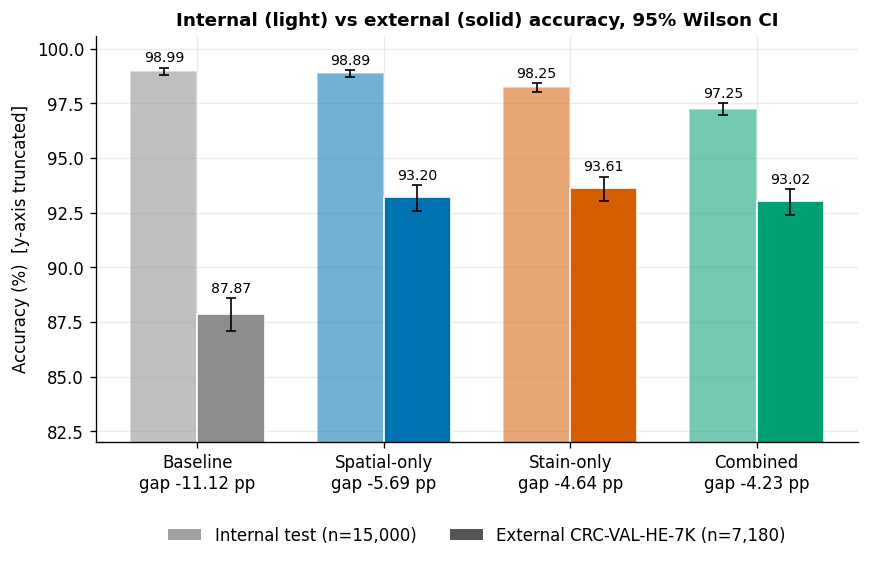

saved fig1_accuracy_internal_vs_external


In [3]:
# [M2] Figure 1: accuracy + CI + gap
# ------------------------------------------------------------------ Fig 1: accuracy + CI + gap
fig, ax = plt.subplots(figsize=(8.2, 4.4))
x = np.arange(len(MODELS)); w = 0.36
for j, (dom, hatch, alpha) in enumerate([("Internal", "", 0.55), ("External", "", 1.0)]):
    for i, m in enumerate(MODELS):
        a, n = s(m, dom, "accuracy"), s(m, dom, "n")
        lo, hi = wilson(a, n)
        ax.bar(x[i] + (j-0.5)*w, a*100, w, color=COL[m], alpha=alpha, edgecolor="white")
        ax.errorbar(x[i] + (j-0.5)*w, a*100, yerr=[[a*100-lo*100], [hi*100-a*100]],
                    color="k", capsize=3, lw=1)
        ax.text(x[i] + (j-0.5)*w, hi*100 + 0.25, f"{a*100:.2f}", ha="center", fontsize=8.5)
ax.set_ylim(82, 100.6); ax.set_xticks(x)
ax.set_xticklabels([f"{m}\ngap {(s(m,'External','accuracy')-s(m,'Internal','accuracy'))*100:+.2f} pp" for m in MODELS])
ax.set_ylabel("Accuracy (%)  [y-axis truncated]")
ax.set_title("Internal (light) vs external (solid) accuracy, 95% Wilson CI")
ax.legend(handles=[plt.Rectangle((0,0),1,1,fc="#555",alpha=.55), plt.Rectangle((0,0),1,1,fc="#555")],
          labels=["Internal test (n=15,000)", "External CRC-VAL-HE-7K (n=7,180)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
save(fig, "fig1_accuracy_internal_vs_external")


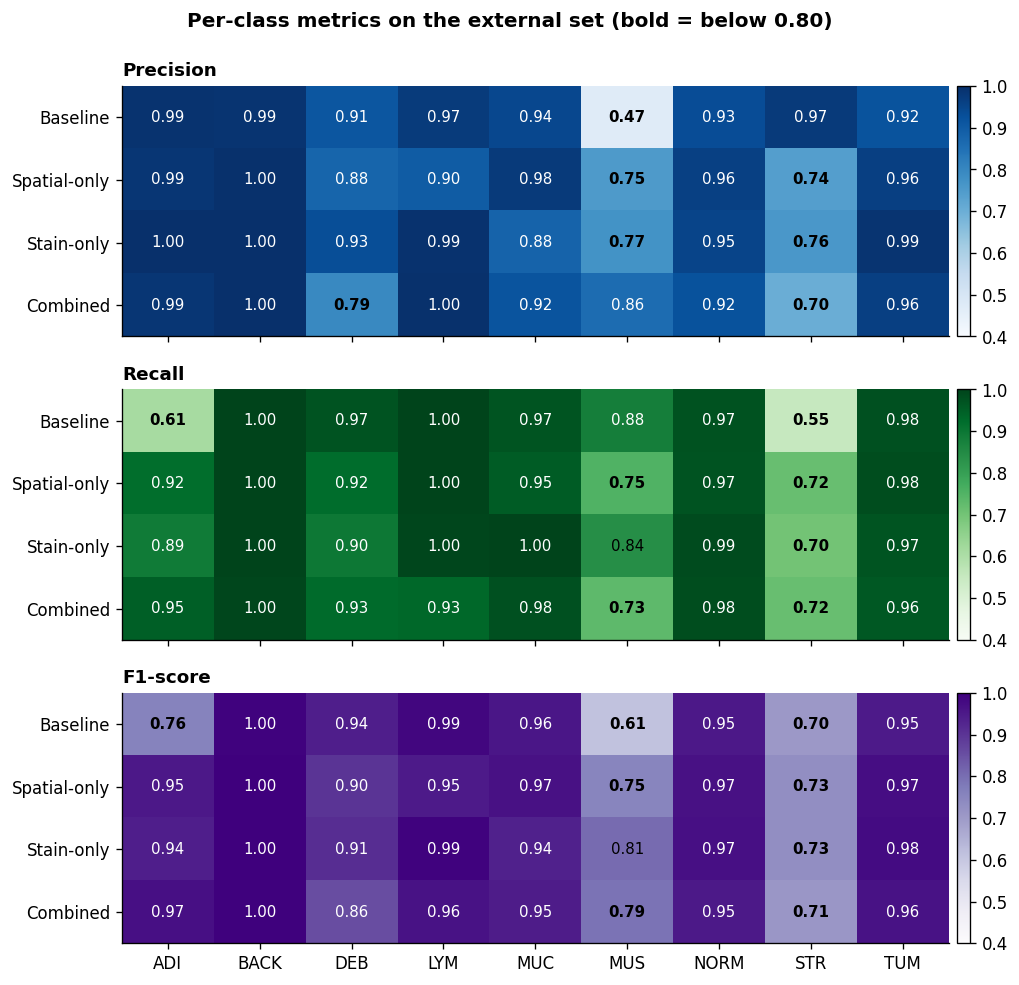

saved fig2_metric_atlas_external


In [4]:
# [M3] Figure 2: metric atlas (external)
# ------------------------------------------------------------------ Fig 2: metric atlas (external)
fig, axes = plt.subplots(3, 1, figsize=(8.6, 8.2), sharex=True)
for ax, met, cmap in zip(axes, ["precision", "recall", "f1"], ["Blues", "Greens", "Purples"]):
    M = np.array([[get(m, "External", c, met) for c in CLASSES] for m in MODELS])
    im = ax.imshow(M, cmap=cmap, vmin=0.4, vmax=1.0, aspect="auto")
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > 0.85 else "black",
                    fontweight="bold" if M[i, j] < 0.8 else "normal")
    ax.set_yticks(range(4)); ax.set_yticklabels(MODELS)
    ax.set_title(met.capitalize() if met != "f1" else "F1-score", loc="left")
    plt.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
axes[-1].set_xticks(range(9)); axes[-1].set_xticklabels(CLASSES)
fig.suptitle("Per-class metrics on the external set (bold = below 0.80)", fontweight="bold", y=0.995)
fig.tight_layout()
save(fig, "fig2_metric_atlas_external")


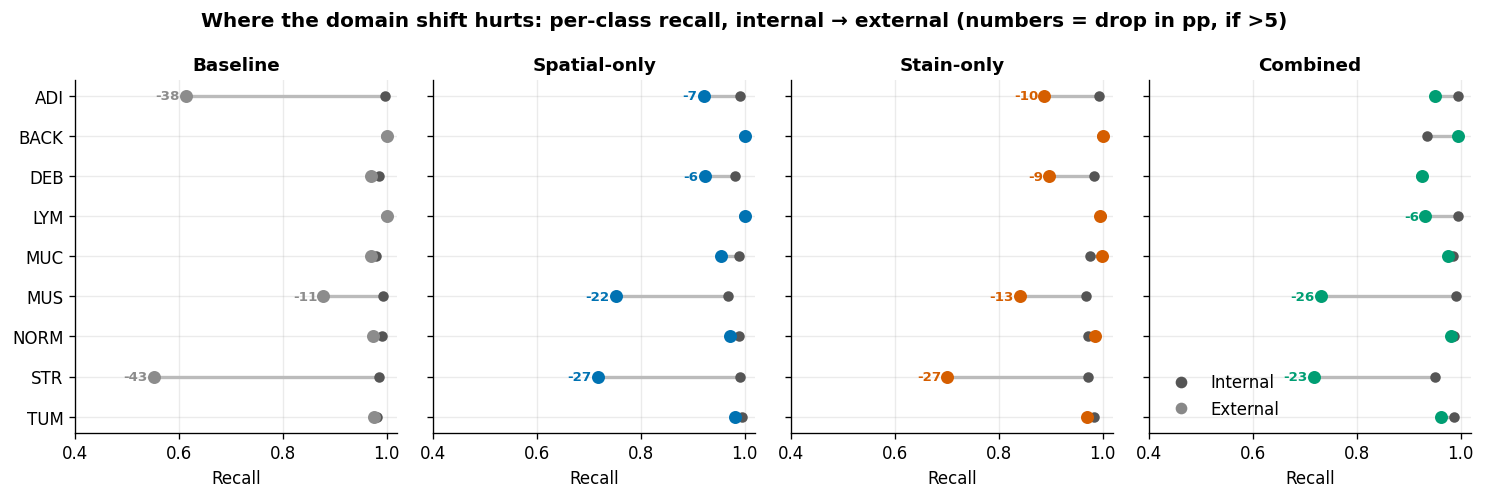

saved fig3_recall_shift_dumbbell


In [5]:
# [M4] Figure 3: dumbbell internal -> external recall
# ------------------------------------------------------------------ Fig 3: dumbbell internal -> external recall
fig, axes = plt.subplots(1, 4, figsize=(12.5, 4.2), sharey=True, sharex=True)
y = np.arange(len(CLASSES))[::-1]
for ax, m in zip(axes, MODELS):
    for yi, c in zip(y, CLASSES):
        a, b = get(m, "Internal", c, "recall"), get(m, "External", c, "recall")
        ax.plot([a, b], [yi, yi], color="#bbbbbb", lw=2, zorder=1)
        ax.scatter(a, yi, color="#555555", s=28, zorder=2)
        ax.scatter(b, yi, color=COL[m], s=46, zorder=3)
        if a - b > 0.05: ax.text(b - 0.012, yi, f"{(b-a)*100:.0f}", ha="right", va="center", fontsize=8, color=COL[m], fontweight="bold")
    ax.set_title(m); ax.set_xlim(0.4, 1.02)
    ax.set_yticks(y); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Recall")
axes[3].legend(handles=[Line2D([],[],marker="o",ls="",color="#555",label="Internal"),
                        Line2D([],[],marker="o",ls="",color="#888",label="External")],
               loc="lower left", frameon=False)
fig.suptitle("Where the domain shift hurts: per-class recall, internal → external (numbers = drop in pp, if >5)",
             fontweight="bold")
fig.tight_layout(); save(fig, "fig3_recall_shift_dumbbell")


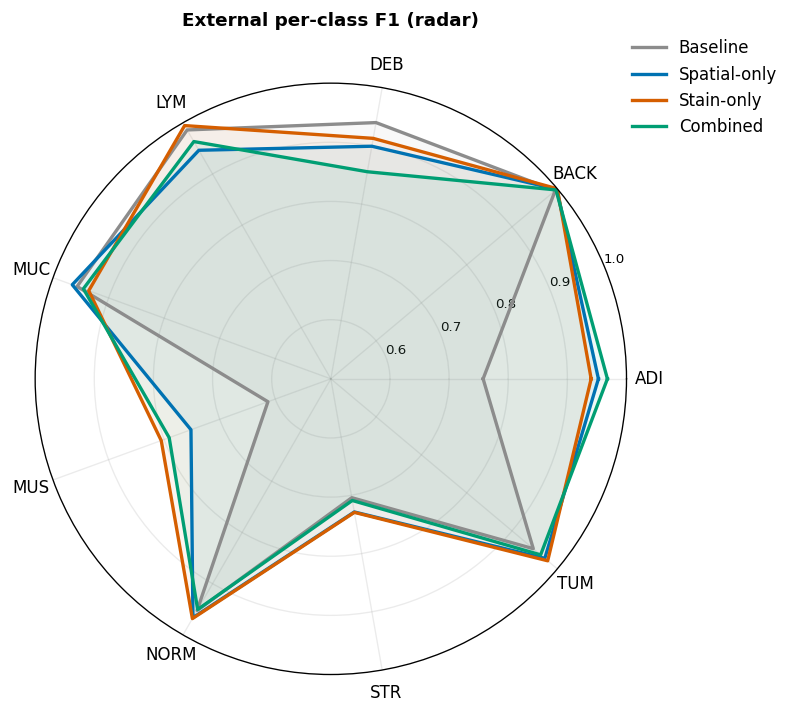

saved fig4_radar_external_f1


In [6]:
# [M5] Figure 4: radar (external F1)
# ------------------------------------------------------------------ Fig 4: radar (external F1)
ang = np.linspace(0, 2*np.pi, len(CLASSES), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(6.4, 6.4)); ax = plt.subplot(111, polar=True)
for m in MODELS:
    v = [get(m, "External", c, "f1") for c in CLASSES]; v += v[:1]
    ax.plot(ang, v, color=COL[m], lw=2, label=m); ax.fill(ang, v, color=COL[m], alpha=0.06)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(CLASSES); ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0]); ax.tick_params(axis="y", labelsize=8)
ax.set_title("External per-class F1 (radar)", pad=18)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.1), frameon=False)
save(fig, "fig4_radar_external_f1")


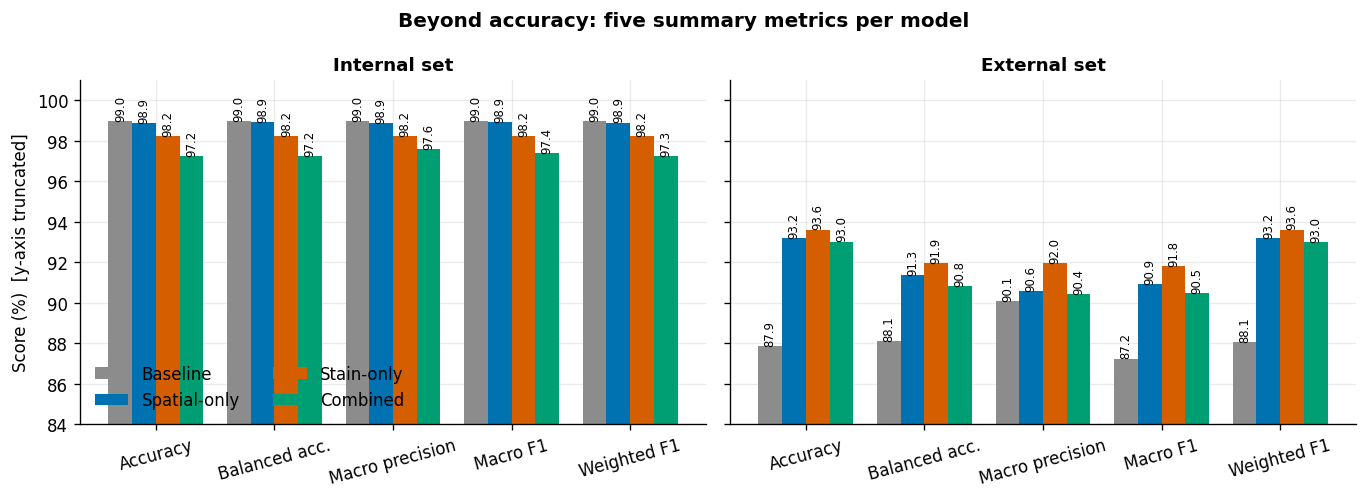

saved fig5_summary_metrics


In [7]:
# [M6] Figure 5: summary metrics
# ------------------------------------------------------------------ Fig 5: summary metrics
mets = [("accuracy", "Accuracy"), ("balanced_acc", "Balanced acc."),
        ("macro_precision", "Macro precision"), ("macro_f1", "Macro F1"), ("weighted_f1", "Weighted F1")]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, dom in zip(axes, ["Internal", "External"]):
    xx = np.arange(len(mets)); w = 0.2
    for i, m in enumerate(MODELS):
        vals = [s(m, dom, k) * 100 for k, _ in mets]
        bars = ax.bar(xx + (i-1.5)*w, vals, w, color=COL[m], label=m)
        for b, v in zip(bars, vals):
            ax.text(b.get_x()+b.get_width()/2, v+0.15, f"{v:.1f}", ha="center", fontsize=7, rotation=90)
    ax.set_xticks(xx); ax.set_xticklabels([l for _, l in mets], rotation=15)
    ax.set_ylim(84, 101); ax.set_title(f"{dom} set")
axes[0].set_ylabel("Score (%)  [y-axis truncated]"); axes[0].legend(frameon=False, ncol=2, loc="lower left")
fig.suptitle("Beyond accuracy: five summary metrics per model", fontweight="bold")
fig.tight_layout(); save(fig, "fig5_summary_metrics")


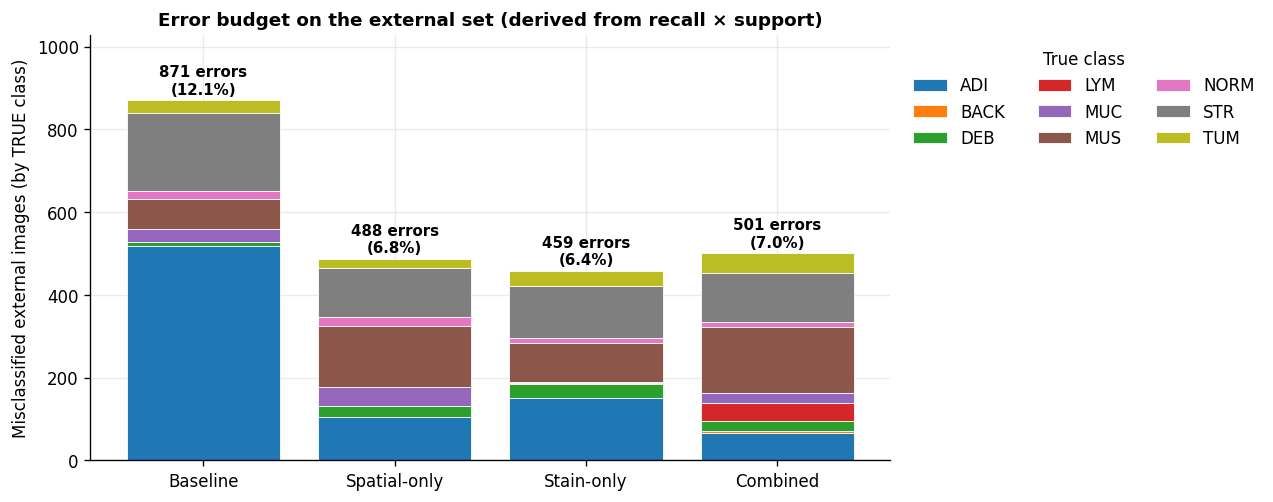

saved fig6_error_budget_external
error-count consistency (derived, from accuracy): {'Baseline': (871, 871), 'Spatial-only': (488, 488), 'Stain-only': (459, 459), 'Combined': (501, 501)}


In [8]:
# [M7] Figure 6: where the errors are (external)
# ------------------------------------------------------------------ Fig 6: where the errors are (external)
fig, ax = plt.subplots(figsize=(8.6, 4.6))
cmap = plt.get_cmap("tab10"); bottom = np.zeros(len(MODELS))
tot_check = {}
for ci, c in enumerate(CLASSES):
    errs = np.array([round((1 - get(m, "External", c, "recall")) * get(m, "External", c, "support")) for m in MODELS])
    ax.bar(MODELS, errs, bottom=bottom, color=cmap(ci), label=c, edgecolor="white", lw=0.5)
    bottom += errs
for i, m in enumerate(MODELS):
    ax.text(i, bottom[i] + 15, f"{int(bottom[i])} errors\n({bottom[i]/7180*100:.1f}%)", ha="center", fontsize=9, fontweight="bold")
    tot_check[m] = (int(bottom[i]), round((1 - s(m, "External", "accuracy")) * 7180))
ax.set_ylabel("Misclassified external images (by TRUE class)"); ax.set_ylim(0, bottom.max() * 1.18)
ax.legend(ncol=3, title="True class", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Error budget on the external set (derived from recall × support)")
save(fig, "fig6_error_budget_external"); print("error-count consistency (derived, from accuracy):", tot_check)


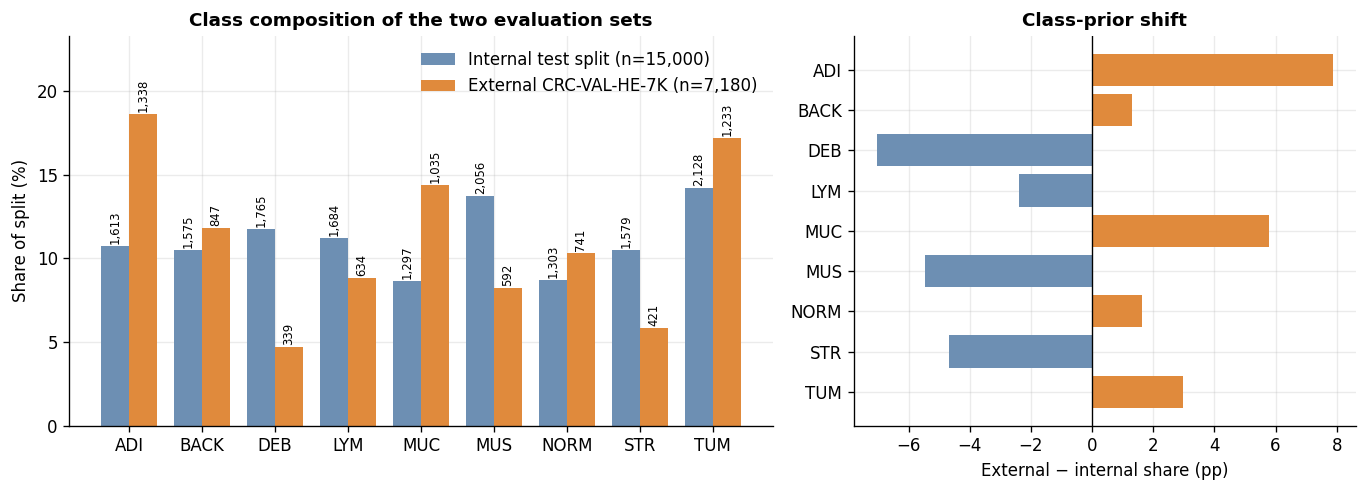

saved fig7_class_distribution_shift


In [9]:
# [M8] Figure 7: class distribution shift
# ------------------------------------------------------------------ Fig 7: class distribution shift
sup_int = per[(per.model == "Baseline") & (per.domain == "Internal")].set_index("class")["support"].reindex(CLASSES)
sup_ext = per[(per.model == "Baseline") & (per.domain == "External")].set_index("class")["support"].reindex(CLASSES)
pi, pe = sup_int / sup_int.sum() * 100, sup_ext / sup_ext.sum() * 100
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
xx = np.arange(9); w = 0.38
axes[0].bar(xx-w/2, pi, w, color="#6d8fb3", label=f"Internal test split (n={sup_int.sum():,})")
axes[0].bar(xx+w/2, pe, w, color="#e08a3c", label=f"External CRC-VAL-HE-7K (n={sup_ext.sum():,})")
for i in range(9):
    axes[0].text(i-w/2, pi.iloc[i]+.3, f"{sup_int.iloc[i]:,}", ha="center", fontsize=7, rotation=90)
    axes[0].text(i+w/2, pe.iloc[i]+.3, f"{sup_ext.iloc[i]:,}", ha="center", fontsize=7, rotation=90)
axes[0].set_xticks(xx); axes[0].set_xticklabels(CLASSES); axes[0].set_ylabel("Share of split (%)")
axes[0].set_ylim(0, max(pi.max(), pe.max())*1.25); axes[0].legend(frameon=False, loc="upper right")
axes[0].set_title("Class composition of the two evaluation sets")
d = (pe - pi)
axes[1].barh(CLASSES[::-1], d[::-1], color=["#e08a3c" if v > 0 else "#6d8fb3" for v in d[::-1]])
axes[1].axvline(0, color="k", lw=0.8); axes[1].set_xlabel("External − internal share (pp)")
axes[1].set_title("Class-prior shift")
fig.tight_layout(); save(fig, "fig7_class_distribution_shift")


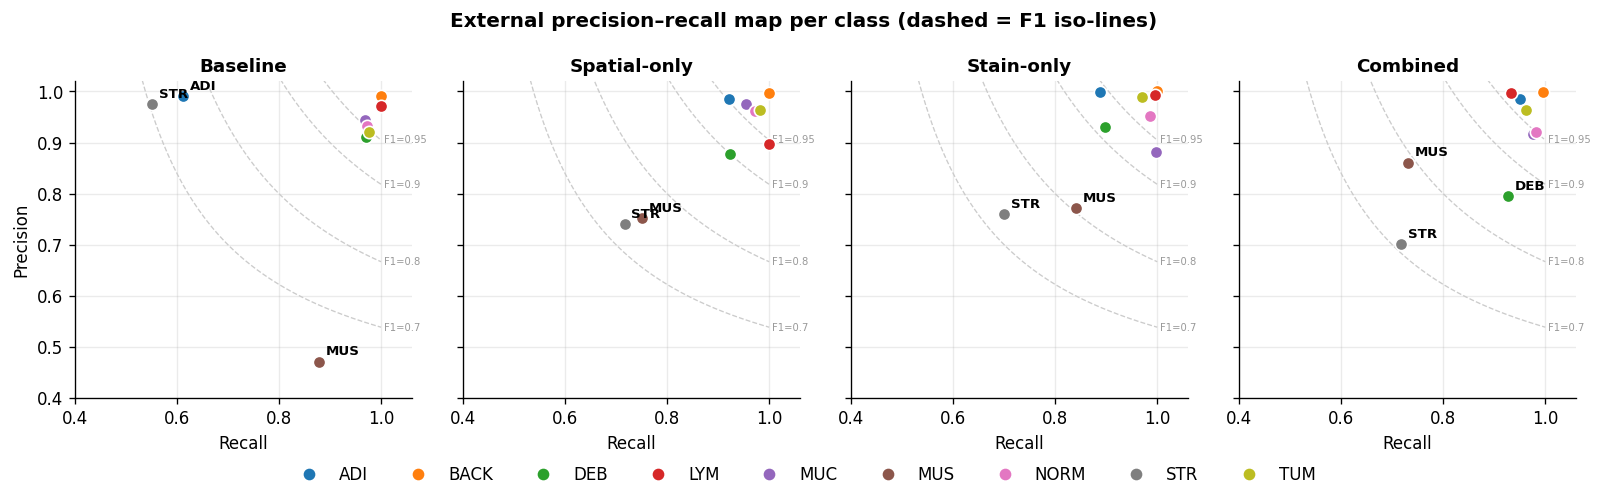

saved fig8_precision_recall_map


In [10]:
# [M9] Figure 8: precision-recall map with F1 iso-curves
# ------------------------------------------------------------------ Fig 8: precision-recall map with F1 iso-curves
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.9), sharex=True, sharey=True)
r = np.linspace(0.3, 1.0, 200)
tabc = plt.get_cmap("tab10")
for ax, m in zip(axes, MODELS):
    for f in [0.7, 0.8, 0.9, 0.95]:
        p = f * r / (2 * r - f); ok = (p > 0) & (p <= 1.05)
        ax.plot(r[ok], p[ok], color="#cccccc", lw=0.8, ls="--")
        ax.text(1.005, f*1.0/(2*1.0-f), f"F1={f}", fontsize=6, color="#999", va="center")
    for ci, c in enumerate(CLASSES):
        pr, rc = get(m, "External", c, "precision"), get(m, "External", c, "recall")
        ax.scatter(rc, pr, color=tabc(ci), s=55, zorder=3, edgecolor="white")
        if min(pr, rc) < 0.85: ax.annotate(c, (rc, pr), xytext=(4, 4), textcoords="offset points", fontsize=8, fontweight="bold")
    ax.set_title(m); ax.set_xlabel("Recall"); ax.set_xlim(0.4, 1.06); ax.set_ylim(0.4, 1.02)
axes[0].set_ylabel("Precision")
fig.legend(handles=[Line2D([],[],marker="o",ls="",color=tabc(i),label=c) for i, c in enumerate(CLASSES)],
           loc="lower center", ncol=9, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("External precision–recall map per class (dashed = F1 iso-lines)", fontweight="bold")
fig.tight_layout(); save(fig, "fig8_precision_recall_map")


In [11]:
# [M10] Metric tables (CSV + LaTeX)
# ------------------------------------------------------------------ tables
tab = sm.set_index(["model", "domain"])[["accuracy", "balanced_acc", "macro_precision", "macro_f1", "weighted_f1"]]
tab.to_csv(f"{A1.out}/metrics_table.csv")
with open(f"{A1.out}/metrics_table.tex", "w") as f:
    f.write(tab.round(4).to_latex(caption="Summary metrics per model and evaluation set.", label="tab:metrics"))
print(tab.round(4))


                       accuracy  balanced_acc  macro_precision  macro_f1  \
model        domain                                                        
Baseline     Internal    0.9899        0.9899           0.9896    0.9897   
             External    0.8787        0.8812           0.9010    0.8724   
Spatial-only Internal    0.9889        0.9894           0.9889    0.9891   
             External    0.9320        0.9135           0.9057    0.9090   
Stain-only   Internal    0.9825        0.9825           0.9821    0.9822   
             External    0.9361        0.9194           0.9195    0.9183   
Combined     Internal    0.9725        0.9723           0.9761    0.9737   
             External    0.9302        0.9081           0.9043    0.9047   

                       weighted_f1  
model        domain                 
Baseline     Internal       0.9899  
             External       0.8807  
Spatial-only Internal       0.9890  
             External       0.9319  
Stain-only   Inte

In [12]:
# [P0] Helper functions for the models: normalisation, Grad-CAM, stain perturbation  (needs torch)
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision import models

CLASSES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]
CLASS_NAMES = {"ADI": "Adipose", "BACK": "Background", "DEB": "Debris", "LYM": "Lymphocytes",
               "MUC": "Mucus", "MUS": "Smooth muscle", "NORM": "Normal mucosa",
               "STR": "Cancer-associated stroma", "TUM": "Tumour epithelium"}
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def normalize(x):
    """x: (B,3,H,W) float in [0,1] on any device."""
    return (x - MEAN.to(x.device)) / STD.to(x.device)


def load_model(path, device):
    m = models.resnet50(weights=None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    m.load_state_dict(torch.load(path, map_location=device))
    return m.to(device).eval()


def stain_perturb(x, brightness=1.0, contrast=1.0, saturation=1.0, hue=0.0):
    """x: (B,3,H,W) in [0,1]. Same operations as torchvision ColorJitter, but with fixed factors."""
    if brightness != 1.0: x = TF.adjust_brightness(x, brightness)
    if contrast != 1.0:   x = TF.adjust_contrast(x, contrast)
    if saturation != 1.0: x = TF.adjust_saturation(x, saturation)
    if hue != 0.0:        x = TF.adjust_hue(x, hue)
    return x.clamp(0, 1)


class GradCAM:
    """Grad-CAM on the last ResNet50 bottleneck (layer4[-1]). Hook lives as long as the object does."""
    def __init__(self, model):
        self.model, self.acts, self.grad = model, None, None
        model.layer4[-1].register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grad", g))

    def __call__(self, x01, class_idx=None):
        """x01: (1,3,H,W) in [0,1]. Returns (cam HxW in [0,1] numpy, probs (9,) numpy, class_idx)."""
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(normalize(x01))
            probs = torch.softmax(logits, 1)[0].detach().cpu().numpy()
            if class_idx is None: class_idx = int(logits.argmax(1))
            logits[0, class_idx].backward()
        w = self.grad.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=x01.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), probs, class_idx


def overlay(img_uint8, cam, alpha=0.45):
    """img_uint8: HxWx3 uint8, cam: HxW in [0,1] -> HxWx3 uint8 heat-map overlay."""
    import matplotlib
    heat = (matplotlib.colormaps["jet"](cam)[..., :3] * 255).astype(np.float32)
    return ((1 - alpha) * img_uint8.astype(np.float32) + alpha * heat).clip(0, 255).astype(np.uint8)


ModuleNotFoundError: No module named 'torchvision'

In [ ]:
# [P1] RUN INFERENCE of the 4 models -> /kaggle/working/crc_predictions.npz  (GPU, ~10-25 min, run once)
import os, numpy as np, torch
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

BASE = "/kaggle/input/datasets/koushgh45/colorectal-cancer-histopathology"
NCT  = f"{BASE}/NCT-CRC-HE-100K/NCT-CRC-HE-100K"
EXT  = f"{BASE}/CRC-VAL-HE-7K/CRC-VAL-HE-7K"
WEIGHTS = {   # paths taken from your notebook
    "baseline": "/kaggle/input/datasets/koushgh45/crc-resnet50-baseline-weights/resnet50_strict_baseline.pth",
    "spatial":  "/kaggle/input/datasets/koushiki123890567/spatial-only-weights/resnet50_spatial_only.pth",
    "stain":    "/kaggle/input/datasets/koushiki123890567/stain-only-weights/resnet50_stain_only.pth",
    "combined": "/kaggle/input/datasets/koushiki123890567/resnet50-combined-augmentation-weights/resnet50_combined.pth",
}
NOTEBOOK_ACC = {  # sanity check against the numbers already in your notebook
    "baseline": (0.9899, 0.8787), "spatial": (0.9889, 0.9320), "stain": (0.9825, 0.9361), "combined": (0.9725, 0.9302)}
OUT_FILE = "/kaggle/working/crc_predictions.npz"
N_FEAT, N_ROB, N_STATS, N_CAM = 2500, 2000, 4500, 8
ROB = {  # perturbation sweeps (training ColorJitter range was 0.8-1.2 and hue +-0.1)
    "brightness": [0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5],
    "contrast":   [0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5],
    "saturation": [0.3, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8],
    "hue":        [-0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15]}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])  # normalisation is done on-GPU
full, ext = datasets.ImageFolder(NCT, tf), datasets.ImageFolder(EXT, tf)
assert full.classes == CLASSES and ext.classes == CLASSES, (full.classes, ext.classes)

# --- identical split to your notebook (seed 42) ---
n = len(full); ntr, nva = int(0.70 * n), int(0.15 * n); nte = n - ntr - nva
tr_ds, va_ds, te_ds = random_split(full, [ntr, nva, nte], generator=torch.Generator().manual_seed(42))
y_full = np.array(full.targets); y_int = y_full[te_ds.indices]; y_ext = np.array(ext.targets)
rng = np.random.RandomState(0)
idx_int = rng.choice(len(te_ds), N_FEAT, replace=False)
idx_ext = rng.choice(len(ext), N_FEAT, replace=False)
out = dict(classes=np.array(CLASSES), int_labels=y_int, ext_labels=y_ext, idx_int=idx_int, idx_ext=idx_ext,
           ext_paths=np.array([p for p, _ in ext.samples]),
           count_full=np.bincount(y_full, minlength=9), count_train=np.bincount(y_full[tr_ds.indices], minlength=9),
           count_val=np.bincount(y_full[va_ds.indices], minlength=9), count_test=np.bincount(y_int, minlength=9),
           count_ext=np.bincount(y_ext, minlength=9))


@torch.no_grad()
def run(model, ds, bs=128):
    feats, probs = [], []
    h = model.avgpool.register_forward_hook(lambda m, i, o: feats.append(o.flatten(1).half().cpu()))
    for x, _ in DataLoader(ds, batch_size=bs, shuffle=False, num_workers=4, pin_memory=True):
        probs.append(torch.softmax(model(normalize(x.to(device, non_blocking=True))).float(), 1).cpu())
    h.remove()
    return torch.cat(probs).numpy(), torch.cat(feats).numpy()


@torch.no_grad()
def rob_eval(model, X, y, kind, level, bs=200):
    correct = 0
    for i in range(0, len(X), bs):
        xb = stain_perturb(X[i:i + bs].to(device).float() / 255, **{kind: level})
        correct += (model(normalize(xb)).argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(X)


# --- fixed external subset for the robustness sweep ---
rob_idx = np.random.RandomState(1).choice(len(ext), N_ROB, replace=False)
print("loading robustness subset ...")
rob_x = torch.stack([(ext[int(i)][0] * 255).round().byte() for i in rob_idx]); rob_y = torch.from_numpy(y_ext[rob_idx])

# --- per-model inference ---
models_ = {}
for key, path in WEIGHTS.items():
    print(f"\n=== {key} ===")
    m = load_model(path, device); models_[key] = m
    for dom, ds, idx in [("int", te_ds, idx_int), ("ext", ext, idx_ext)]:
        p, f = run(m, ds); out[f"{key}_{dom}_probs"] = p; out[f"{key}_{dom}_feats"] = f[idx]
        yy = y_int if dom == "int" else y_ext
        acc = float((p.argmax(1) == yy).mean()); ref = NOTEBOOK_ACC[key][0 if dom == "int" else 1]
        flag = "" if abs(acc - ref) < 0.002 else "   <-- DIFFERS from notebook, check weights/split!"
        print(f"  {dom} accuracy {acc:.4f} (notebook {ref:.4f}){flag}")
    for kind, levels in ROB.items():
        out[f"rob_{key}_{kind}"] = np.array([rob_eval(m, rob_x, rob_y, kind, lv) for lv in levels])
        print(f"  robustness {kind}: {np.round(out[f'rob_{key}_{kind}'], 3)}")
for kind, levels in ROB.items(): out[f"rob_levels_{kind}"] = np.array(levels)

# --- dataset statistics (colour / stain) ---
@torch.no_grad()
def image_stats(ds, idx):
    rgb, sat, od, lab = [], [], [], []
    for x, y in DataLoader(Subset(ds, idx), batch_size=128, num_workers=4):
        x = x.to(device); mx, mn = x.max(1).values, x.min(1).values
        rgb.append(x.mean((2, 3)).cpu()); sat.append(((mx - mn) / (mx + 1e-6)).mean((1, 2)).cpu())
        od.append((-torch.log10((x * 255 + 1) / 256)).mean((2, 3)).cpu()); lab.append(y)
    return dict(rgb=torch.cat(rgb).numpy(), sat=torch.cat(sat).numpy(), od=torch.cat(od).numpy(), labels=torch.cat(lab).numpy())
for dom, ds in [("int", te_ds), ("ext", ext)]:
    sel = np.random.RandomState(2).choice(len(ds), min(N_STATS, len(ds)), replace=False)
    for k, v in image_stats(ds, sel).items(): out[f"stats_{dom}_{k}"] = v

# --- sample image grids (4 per class per domain) ---
def grid(ds, labels):
    g = np.zeros((9, 4, 224, 224, 3), np.uint8); r = np.random.RandomState(3)
    for c in range(9):
        for j, i in enumerate(r.choice(np.where(labels == c)[0], 4, replace=False)):
            g[c, j] = (ds[int(i)][0].permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
    return g
out["grid_int"], out["grid_ext"] = grid(te_ds, y_int), grid(ext, y_ext)

# --- Grad-CAM: external images Baseline gets wrong but Combined gets right ---
pb, pc = out["baseline_ext_probs"].argmax(1), out["combined_ext_probs"].argmax(1)
cand = np.where((pb != y_ext) & (pc == y_ext))[0]; r = np.random.RandomState(4); r.shuffle(cand)
picked, per_class = [], {}
for i in cand:
    if per_class.get(y_ext[i], 0) < 2: picked.append(int(i)); per_class[y_ext[i]] = per_class.get(y_ext[i], 0) + 1
    if len(picked) == N_CAM: break
cams = {k: GradCAM(m) for k, m in models_.items()}
imgs, maps, preds = [], [], []
for i in picked:
    x = ext[i][0].unsqueeze(0).to(device); imgs.append((x[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8))
    mm, pp = [], []
    for k in WEIGHTS:
        cam, _, ci = cams[k](x); mm.append(cam.astype(np.float16)); pp.append(ci)
    maps.append(mm); preds.append(pp)
out.update(cam_idx=np.array(picked), cam_imgs=np.array(imgs), cam_maps=np.array(maps), cam_preds=np.array(preds),
           cam_true=y_ext[picked], cam_model_order=np.array(list(WEIGHTS)))

np.savez_compressed(OUT_FILE, **out)
print("\nSaved", OUT_FILE, f"({os.path.getsize(OUT_FILE)/1e6:.0f} MB). Download it and run 03_make_plots_from_predictions.py")


In [ ]:
# [Q0] Load predictions + shared helpers for the prediction-based figures
import os, traceback, itertools
import numpy as np, pandas as pd
import matplotlib as mpl; import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import binomtest, gaussian_kde
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.manifold import TSNE

class _A3:
    npz = "/kaggle/working/crc_predictions.npz"
    out = "/kaggle/working/method_comparison_predictions"
    tsne_models = ["Baseline", "Combined"]
    boot = 2000
A3 = _A3(); os.makedirs(A3.out, exist_ok=True)
D = np.load(A3.npz, allow_pickle=True)

CLASSES = list(D["classes"]); K = len(CLASSES)
MODELS = ["Baseline", "Spatial-only", "Stain-only", "Combined"]
KEY = {"Baseline": "baseline", "Spatial-only": "spatial", "Stain-only": "stain", "Combined": "combined"}
COL = {"Baseline": "#8c8c8c", "Spatial-only": "#0072B2", "Stain-only": "#D55E00", "Combined": "#009E73"}
CCOL = plt.get_cmap("tab10")
mpl.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
y = {"int": D["int_labels"], "ext": D["ext_labels"]}
def P(m, dom):
    p = D[f"{KEY[m]}_{dom}_probs"].astype(np.float64); return p / p.sum(1, keepdims=True)
def pred(m, dom): return P(m, dom).argmax(1)
def savep(fig, name): fig.savefig(f"{A3.out}/{name}.png"); fig.savefig(f"{A3.out}/{name}.pdf"); plt.show(); plt.close(fig); print("  saved", name)

def macro_f1(yt, yp):
    cm = np.bincount(yt * K + yp, minlength=K * K).reshape(K, K); tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    return np.mean(2 * prec * rec / np.maximum(prec + rec, 1e-12))
def ece(p, yt, bins=15):
    conf, ok = p.max(1), p.argmax(1) == yt; e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e
def brier(p, yt): return np.mean(((p - np.eye(K)[yt]) ** 2).sum(1))


In [ ]:
# [Q1] Figure: confusion matrices
def confusion_grid():
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    for r, (dom, cmap, ttl) in enumerate([("int", "Blues", "Internal"), ("ext", "Oranges", "External")]):
        for c, m in enumerate(MODELS):
            cm = np.bincount(y[dom] * K + pred(m, dom), minlength=K * K).reshape(K, K).astype(float)
            cmn = cm / cm.sum(1, keepdims=True); ax = axes[r, c]
            ax.imshow(cmn, cmap=cmap, vmin=0, vmax=1); ax.grid(False)
            for i in range(K):
                for j in range(K):
                    if cmn[i, j] >= 0.005:
                        ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=6.5,
                                color="white" if cmn[i, j] > 0.6 else "black")
            ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=60, fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=8)
            ax.set_title(f"{m} — {ttl}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    fig.tight_layout(); savep(fig, "p1_confusion_matrices")


confusion_grid()


In [ ]:
# [Q2] Figure: ROC / PR / per-class AUC (external)
def roc_pr():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6)); grid = np.linspace(0, 1, 500); aucs = np.zeros((len(MODELS), K))
    for m in MODELS:
        p, Y = P(m, "ext"), np.eye(K)[y["ext"]]
        tprs = []
        for k in range(K):
            f, t, _ = roc_curve(Y[:, k], p[:, k]); tprs.append(np.interp(grid, f, t)); aucs[MODELS.index(m), k] = roc_auc_score(Y[:, k], p[:, k])
        axes[0].plot(grid, np.mean(tprs, 0), color=COL[m], lw=2, label=f"{m} (macro AUC {aucs[MODELS.index(m)].mean():.4f})")
        rec = np.linspace(0, 1, 500); prs = []
        for k in range(K):
            pr, rc, _ = precision_recall_curve(Y[:, k], p[:, k]); prs.append(np.interp(rec, rc[::-1], pr[::-1]))
        axes[1].plot(rec, np.mean(prs, 0), color=COL[m], lw=2, label=f"{m} (mAP {np.mean([average_precision_score(Y[:,k], p[:,k]) for k in range(K)]):.4f})")
    axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlim(0, 0.3); axes[0].set_ylim(0.7, 1.005)
    axes[0].set_xlabel("False-positive rate (zoomed to 0–0.3)"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("Macro one-vs-rest ROC (external)"); axes[0].legend(frameon=False, loc="lower right", fontsize=8)
    axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_ylim(0.6, 1.005); axes[1].set_title("Macro precision–recall (external)"); axes[1].legend(frameon=False, loc="lower left", fontsize=8)
    im = axes[2].imshow(aucs, cmap="viridis", vmin=0.9, vmax=1.0, aspect="auto"); axes[2].grid(False)
    for i in range(len(MODELS)):
        for j in range(K): axes[2].text(j, i, f"{aucs[i,j]:.3f}", ha="center", va="center", fontsize=7.5, color="white" if aucs[i, j] < 0.97 else "black")
    axes[2].set_xticks(range(K)); axes[2].set_xticklabels(CLASSES); axes[2].set_yticks(range(len(MODELS))); axes[2].set_yticklabels(MODELS); axes[2].set_title("Per-class AUC (external)")
    plt.colorbar(im, ax=axes[2], fraction=0.04); fig.tight_layout(); savep(fig, "p2_roc_pr_auc_external")


roc_pr()


In [ ]:
# [Q3] Figure: calibration
def calibration():
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.6), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
    for c, m in enumerate(MODELS):
        p = P(m, "ext"); conf, ok = p.max(1), p.argmax(1) == y["ext"]; edges = np.linspace(0, 1, 11); xs, ys, ns = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            mk = (conf > lo) & (conf <= hi)
            if mk.sum() >= 5: xs.append(conf[mk].mean()); ys.append(ok[mk].mean()); ns.append(mk.sum())
        ax = axes[0, c]; ax.plot([0, 1], [0, 1], "k:", lw=1); ax.plot(xs, ys, "o-", color=COL[m], lw=2)
        ax.set_title(f"{m}\nECE = {ece(p, y['ext']):.3f}, Brier = {brier(p, y['ext']):.3f}", fontsize=10); ax.set_ylim(0, 1.02); ax.set_xlim(0.1, 1.0)
        if c == 0: ax.set_ylabel("Accuracy in bin")
        axes[1, c].hist(conf, bins=20, range=(0, 1), color=COL[m], alpha=.8); axes[1, c].set_xlabel("Confidence"); axes[1, c].set_yscale("log")
        if c == 0: axes[1, c].set_ylabel("Count (log)")
    fig.suptitle("Reliability diagrams on the external set (below the diagonal = over-confident)", fontweight="bold"); fig.tight_layout(); savep(fig, "p3_calibration_external")


calibration()


In [ ]:
# [Q4] Figure: t-SNE + domain separability
def domain_auc(m):
    X = np.vstack([D[f"{KEY[m]}_int_feats"], D[f"{KEY[m]}_ext_feats"]]).astype(np.float32); d = np.r_[np.zeros(len(D["idx_int"])), np.ones(len(D["idx_ext"]))]
    pipe = make_pipeline(StandardScaler(), PCA(64, random_state=0), LogisticRegression(max_iter=2000))
    return roc_auc_score(d, cross_val_predict(pipe, X, d, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1])
def tsne():
    ms = [m for m in A3.tsne_models if m in MODELS]; fig, axes = plt.subplots(len(ms), 2, figsize=(11, 5 * len(ms)), squeeze=False)
    yl = np.r_[y["int"][D["idx_int"]], y["ext"][D["idx_ext"]]]; dom = np.r_[np.zeros(len(D["idx_int"])), np.ones(len(D["idx_ext"]))]
    for r, m in enumerate(ms):
        F = np.vstack([D[f"{KEY[m]}_int_feats"], D[f"{KEY[m]}_ext_feats"]]).astype(np.float32)
        Z = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(PCA(50, random_state=0).fit_transform(F))
        for k in range(K): axes[r, 0].scatter(*Z[yl == k].T, s=4, color=CCOL(k), label=CLASSES[k], alpha=.7)
        axes[r, 0].set_title(f"{m}: coloured by tissue class"); axes[r, 0].legend(markerscale=3, fontsize=7, frameon=False, ncol=3)
        for v, c_, lb in [(0, "#3b6ea5", "Internal"), (1, "#e08a3c", "External")]: axes[r, 1].scatter(*Z[dom == v].T, s=4, color=c_, label=lb, alpha=.55)
        axes[r, 1].set_title(f"{m}: coloured by dataset (domain AUC {domain_auc(m):.3f})"); axes[r, 1].legend(markerscale=3, frameon=False)
        for a in axes[r]: a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.tight_layout(); savep(fig, "p4_tsne_feature_space")


tsne()   # takes a few minutes


In [ ]:
# [Q5] Figure: robustness curves
def robustness():
    TR = {"brightness": (0.8, 1.2), "contrast": (0.8, 1.2), "saturation": (0.8, 1.2), "hue": (-0.1, 0.1)}
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
    for ax, kind in zip(axes, TR):
        lv = D[f"rob_levels_{kind}"]; ax.axvspan(*TR[kind], color="#e6e6e6", alpha=.7, label="ColorJitter training range")
        for m in MODELS: ax.plot(lv, D[f"rob_{KEY[m]}_{kind}"] * 100, "o-", color=COL[m], lw=2, label=m)
        ax.set_title(kind.capitalize()); ax.set_xlabel("Factor" if kind != "hue" else "Hue shift")
    axes[0].set_ylabel("External accuracy (%)"); axes[0].legend(frameon=False, fontsize=8, loc="lower center")
    fig.suptitle("Synthetic stain-shift stress test (external subset; grey = range seen by jitter-trained models)", fontweight="bold"); fig.tight_layout(); savep(fig, "p5_robustness_curves")


robustness()


In [ ]:
# [Q6] Figure: bootstrap CI + paired tests
def stats_tests():
    rng = np.random.RandomState(0); n = len(y["ext"]); B = A3.boot; preds = {m: pred(m, "ext") for m in MODELS}
    idx = rng.randint(0, n, (B, n)); acc = {m: np.array([(preds[m][i] == y["ext"][i]).mean() for i in idx]) for m in MODELS}
    f1b = {m: np.array([macro_f1(y["ext"][i], preds[m][i]) for i in idx]) for m in MODELS}
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.2, 1]})
    for ax, (nm, dd) in zip(axes[:1], [("Accuracy", acc)]):
        for i, m in enumerate(MODELS):
            pt = (preds[m] == y["ext"]).mean() * 100; lo, hi = np.percentile(dd[m], [2.5, 97.5]) * 100
            ax.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", color=COL[m], capsize=4, lw=2, ms=8); ax.text(hi + .15, i, f"{pt:.2f} [{lo:.2f}, {hi:.2f}]", va="center", fontsize=8.5)
        ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(MODELS); ax.invert_yaxis(); ax.set_xlabel("External accuracy (%), 95% bootstrap CI"); ax.set_xlim(86, 97.5); ax.set_title("Accuracy with bootstrap CI")
    pairs = list(itertools.combinations(MODELS, 2)); ax = axes[1]
    for i, (a, b) in enumerate(pairs):
        d = (acc[b] - acc[a]) * 100; lo, hi = np.percentile(d, [2.5, 97.5]); pt = d.mean(); sig = lo > 0 or hi < 0
        ax.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", color="#c0392b" if sig else "#555", capsize=4, lw=2, ms=7)
    ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(pairs))); ax.set_yticklabels([f"{b} − {a}" for a, b in pairs]); ax.invert_yaxis()
    ax.set_xlabel("Paired accuracy difference (pp), 95% CI  (red = CI excludes 0)"); ax.set_title("Which differences are real?")
    pm = np.ones((len(MODELS), len(MODELS)))
    for (a, b) in pairs:
        ca, cb = preds[a] == y["ext"], preds[b] == y["ext"]; b01, c10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
        p = binomtest(b01, b01 + c10, 0.5).pvalue if b01 + c10 else 1.0; pm[MODELS.index(a), MODELS.index(b)] = pm[MODELS.index(b), MODELS.index(a)] = p
    np.fill_diagonal(pm, np.nan)
    ax = axes[2]; im = ax.imshow(np.log10(np.clip(pm, 1e-12, 1)), cmap="RdYlGn", vmin=-6, vmax=0); ax.grid(False)
    for i in range(len(MODELS)):
        for j in range(len(MODELS)):
            if i != j: ax.text(j, i, f"{pm[i,j]:.3f}" if pm[i, j] >= 0.001 else "<0.001", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS, rotation=30); ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(MODELS)
    ax.set_title("McNemar exact p (external)\n(6 tests: Bonferroni threshold 0.0083)", fontsize=10); fig.tight_layout(); savep(fig, "p6_bootstrap_and_mcnemar")
    return {m: (np.percentile(acc[m], [2.5, 97.5]), np.percentile(f1b[m], [2.5, 97.5])) for m in MODELS}


ci = stats_tests()


In [ ]:
# [Q7] Figure: extended metric table
def metric_table(ci=None):
    rows = []
    for m in MODELS:
        r = {"model": m}
        for dom in ["int", "ext"]:
            p, yy = P(m, dom), y[dom]; pr = p.argmax(1); cm = np.bincount(yy * K + pr, minlength=K * K).reshape(K, K)
            r[f"{dom}_acc"] = (pr == yy).mean(); r[f"{dom}_bal_acc"] = np.mean(np.diag(cm) / cm.sum(1)); r[f"{dom}_macro_f1"] = macro_f1(yy, pr)
            r[f"{dom}_mcc"] = matthews_corrcoef(yy, pr); r[f"{dom}_kappa"] = cohen_kappa_score(yy, pr)
            r[f"{dom}_auc"] = roc_auc_score(yy, p, multi_class="ovr", average="macro"); r[f"{dom}_logloss"] = log_loss(yy, p, labels=range(K))
            r[f"{dom}_ece"] = ece(p, yy)
        r["domain_auc"] = domain_auc(m)
        r["rob_mean_acc"] = np.mean(np.concatenate([D[f"rob_{KEY[m]}_{k}"] for k in ["brightness", "contrast", "saturation", "hue"]]))
        if ci: r["ext_acc_CI95"] = f"[{ci[m][0][0]*100:.2f}, {ci[m][0][1]*100:.2f}]"; r["ext_macroF1_CI95"] = f"[{ci[m][1][0]:.4f}, {ci[m][1][1]:.4f}]"
        rows.append(r)
    df = pd.DataFrame(rows).set_index("model"); df.to_csv(f"{A3.out}/extended_metrics.csv")
    open(f"{A3.out}/extended_metrics.tex", "w").write(df.T.to_latex(float_format="%.4f", caption="Extended metrics.", label="tab:ext_metrics"))
    print(df.T.round(4).to_string())


metric_table(ci)


In [ ]:
# [Q9] Figure: Grad-CAM gallery
def gradcam_gallery():
    imgs, maps, preds, true = D["cam_imgs"], D["cam_maps"].astype(np.float32), D["cam_preds"], D["cam_true"]; order = list(D["cam_model_order"]); K_ = len(imgs)
    import matplotlib.cm as cm
    fig, axes = plt.subplots(K_, 5, figsize=(11.5, 2.4 * K_), squeeze=False)
    for i in range(K_):
        axes[i, 0].imshow(imgs[i]); axes[i, 0].set_title(f"true: {CLASSES[true[i]]}", fontsize=9, fontweight="bold")
        for j, m in enumerate(MODELS):
            k = order.index(KEY[m]); heat = cm.jet(maps[i, k])[..., :3]; ov = 0.55 * imgs[i] / 255 + 0.45 * heat
            axes[i, j + 1].imshow(ov.clip(0, 1)); ok = preds[i, k] == true[i]
            axes[i, j + 1].set_title(f"{m}: {CLASSES[preds[i, k]]}", fontsize=9, color="#1a7f37" if ok else "#c0392b", fontweight="bold")
        for a in axes[i]: a.axis("off")
    fig.suptitle("Grad-CAM on external images that Baseline misclassifies but Combined gets right\n(heat-map = evidence for each model's own predicted class)", fontweight="bold")
    fig.tight_layout(); savep(fig, "p7_gradcam_gallery")

gradcam_gallery()
